# Notebook 7 - Huấn luyện XGBoost & Báo cáo Tổng kết Benchmark Toàn diện (Bước 6.5 & Tổng kết Toàn Dự án)

**Mục tiêu chính của Notebook 7:**
1. Huấn luyện mô hình chuẩn công nghiệp hàng đầu cho dữ liệu bảng: **XGBoost (Extreme Gradient Boosting - Chen & Guestrin, 2016)**.
2. Tìm hiểu cơ chế toán học vượt trội của XGBoost so với Gradient Boosting truyền thống:
   - **Khai triển Taylor bậc 2** của hàm mất mát: Sử dụng cả đạo hàm bậc một (Gradient $g_i$) và đạo hàm bậc hai (Hessian $h_i$).
   - **Điều chuẩn hóa hàm phạt trực tiếp trên cấu trúc lá cây**: $\Omega(f) = \gamma T + \frac{1}{2} \lambda \sum w_j^2 + \alpha \sum |w_j|$ giúp kiểm soát triệt để hiện tượng quá khớp.
   - **Thuật toán Histogram Binning (`tree_method='hist'`)**: Tăng tốc độ huấn luyện lên hàng chục lần.
3. So sánh hiệu năng của XGBoost trên 2 không gian: **One-Hot (153 đặc trưng)** vs **Weight of Evidence - WoE (50 đặc trưng)**.
4. Tinh chỉnh siêu tham số (**Hyperparameter Tuning**) với `TimeSeriesSplit(n_splits=3)` hoàn toàn bên trong tập `train` (2012-01 đến 2015-05) với `refit=True`, đảm bảo tuyệt đối không có rò rỉ dữ liệu tương lai.
5. Phân tích độ quan trọng của đặc trưng (**XGBoost Feature Importance: Gain, Weight, Cover**).
6. **BẢNG TỔNG HỢP ĐỐI ĐẦU BENCHMARK TOÀN DIỆN CẢ 5 HỌ MÔ HÌNH**:
   - Đối đầu trực diện giữa: **Hồi quy Logistic**, **Cây Quyết Định**, **Rừng Ngẫu Nhiên**, **HistGradientBoosting**, và **XGBoost**.
7. **ĐƯỜNG CONG ROC SO SÁNH TRỰC DIỆN CẢ 5 HỌ MÔ HÌNH** và đưa ra kết luận, khuyến nghị triển khai thực tế.


In [1]:
from pathlib import Path
import json
import time
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import xgboost as xgb
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import (
    roc_auc_score, roc_curve, brier_score_loss, log_loss
)
import joblib

print(f"Đã nạp toàn bộ thư viện! Phiên bản XGBoost: {xgb.__version__}")


Đã nạp toàn bộ thư viện! Phiên bản XGBoost: 3.4.1


In [2]:
ROOT = Path("..") if Path("../data").exists() else Path(".")
DATA_DIR = ROOT / "data" / "processed"
ARTIFACTS_DIR = ROOT / "artifacts"
FIGURES_DIR = ARTIFACTS_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42

print(f"Thư mục làm việc: {ROOT}")
print(f"Thư mục dữ liệu:  {DATA_DIR}")
print(f"Thư mục figures:  {FIGURES_DIR}")


Thư mục làm việc: .
Thư mục dữ liệu:  data/processed
Thư mục figures:  artifacts/figures


---
## 1. Nạp dữ liệu Huấn luyện & Validation

Dữ liệu nạp từ các ma trận đã chia tách nghiêm ngặt theo thời gian ở Bước 1–5:
- `X_train.npy`, `X_val.npy`: Bộ dữ liệu One-Hot (153 đặc trưng).
- `X_train_woe.npy`, `X_val_woe.npy`: Bộ dữ liệu WoE (50 đặc trưng).


In [3]:
# 1. Nạp ma trận One-Hot (153 đặc trưng)
X_train_oh = np.load(DATA_DIR / "X_train.npy")
y_train = np.load(DATA_DIR / "y_train.npy")
X_val_oh = np.load(DATA_DIR / "X_val.npy")
y_val = np.load(DATA_DIR / "y_val.npy")

# 2. Nạp ma trận WoE (50 đặc trưng)
X_train_woe = np.load(DATA_DIR / "X_train_woe.npy")
X_val_woe = np.load(DATA_DIR / "X_val_woe.npy")

feature_info = json.loads((DATA_DIR / "feature_names.json").read_text())
numeric_features = feature_info["numeric"]
categorical_features = feature_info["categorical"]
feature_names_woe = numeric_features + categorical_features

print(f"Tập Train: X_train_oh = {X_train_oh.shape}, y_train = {y_train.shape}")
print(f"Tập Val:   X_val_oh   = {X_val_oh.shape},   y_val   = {y_val.shape}")
print(f"Tập WoE:   Train = {X_train_woe.shape}, Val = {X_val_woe.shape}")


Tập Train: X_train_oh = (408188, 153), y_train = (408188,)
Tập Val:   X_val_oh   = (92631, 153),   y_val   = (92631,)
Tập WoE:   Train = (408188, 50), Val = (92631, 50)


In [4]:
def evaluate_credit_ranking(y_true, proba):
    """Tính toán các thước đo phân hạng rủi ro tín dụng chuẩn mực."""
    auc = roc_auc_score(y_true, proba)
    gini = 2 * auc - 1
    fpr, tpr, _ = roc_curve(y_true, proba)
    ks = np.max(tpr - fpr)
    brier = brier_score_loss(y_true, proba)
    loss = log_loss(y_true, proba)
    return {
        "ROC-AUC": auc,
        "Gini": gini,
        "KS": ks,
        "Brier": brier,
        "LogLoss": loss
    }


---
## 2. Giới thiệu Cơ chế Hoạt động của XGBoost

### 2.1 Khai triển Taylor bậc 2 của Hàm mất mát
Trong Gradient Boosting truyền thống, hàm mất mát chỉ được xấp xỉ bằng đạo hàm bậc 1 ($g_i$). Ngược lại, XGBoost sử dụng khai triển Taylor bậc 2:
$$\mathcal{L}^{(t)} \approx \sum_{i=1}^n \left[ l(y_i, \hat{y}_i^{(t-1)}) + g_i f_t(x_i) + \frac{1}{2} h_i f_t^2(x_i) \right] + \Omega(f_t)$$
Trong đó:
- $g_i = \partial_{\hat{y}^{(t-1)}} l(y_i, \hat{y}^{(t-1)})$ là **Gradient bậc 1**.
- $h_i = \partial^2_{\hat{y}^{(t-1)}} l(y_i, \hat{y}^{(t-1)})$ là **Hessian bậc 2** (phản ánh độ cong của hàm mất mát, giúp bước nhảy chính xác hơn nhiều).

### 2.2 Hàm phạt điều chuẩn cấu trúc cây (Regularization)
$$\Omega(f) = \gamma T + \frac{1}{2} \lambda \sum_{j=1}^T w_j^2 + \alpha \sum_{j=1}^T |w_j|$$
- $T$: Số lượng lá của cây (phạt cây có quá nhiều lá).
- $w_j$: Trọng số dự đoán tại lá thứ $j$.
- $\lambda$ (`reg_lambda`): Phạt $L_2$ trên trọng số lá.
- $\alpha$ (`reg_alpha`): Phạt $L_1$ trên trọng số lá.


---
## 3. Huấn luyện Baseline XGBoost trên One-Hot vs WoE

Chúng ta huấn luyện mô hình XGBoost tiêu chuẩn (`n_estimators=100`, `learning_rate=0.08`, `max_depth=5`, `tree_method='hist'`) trên cả 2 không gian đặc trưng:


In [5]:
xgb_base_params = {
    "n_estimators": 100,
    "learning_rate": 0.08,
    "max_depth": 5,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "tree_method": "hist",
    "random_state": SEED,
    "n_jobs": 4,
    "eval_metric": "auc"
}

print("1. Huấn luyện Baseline XGBoost trên One-Hot (153 đặc trưng)...")
t0 = time.time()
xgb_base_oh = xgb.XGBClassifier(**xgb_base_params)
xgb_base_oh.fit(X_train_oh, y_train)
t_base_oh = time.time() - t0

val_prob_base_oh = xgb_base_oh.predict_proba(X_val_oh)[:, 1]
m_base_oh = evaluate_credit_ranking(y_val, val_prob_base_oh)
print(f"  -> Fit xong trong {t_base_oh:.2f}s | Val AUC: {m_base_oh['ROC-AUC']:.4f} | KS: {m_base_oh['KS']:.2%}")

print("\n2. Huấn luyện Baseline XGBoost trên WoE (50 đặc trưng)...")
t0 = time.time()
xgb_base_woe = xgb.XGBClassifier(**xgb_base_params)
xgb_base_woe.fit(X_train_woe, y_train)
t_base_woe = time.time() - t0

val_prob_base_woe = xgb_base_woe.predict_proba(X_val_woe)[:, 1]
m_base_woe = evaluate_credit_ranking(y_val, val_prob_base_woe)
print(f"  -> Fit xong trong {t_base_woe:.2f}s | Val AUC: {m_base_woe['ROC-AUC']:.4f} | KS: {m_base_woe['KS']:.2%}")


1. Huấn luyện Baseline XGBoost trên One-Hot (153 đặc trưng)...


  -> Fit xong trong 2.69s | Val AUC: 0.7002 | KS: 29.45%

2. Huấn luyện Baseline XGBoost trên WoE (50 đặc trưng)...


  -> Fit xong trong 1.48s | Val AUC: 0.7092 | KS: 30.79%


---
## 4. Tinh chỉnh Siêu tham số XGBoost với TimeSeriesSplit

Để đảm bảo tính khách quan và **không rò rỉ dữ liệu tương lai**, toàn bộ quá trình tinh chỉnh siêu tham số được thực hiện nghiêm ngặt trên tập `train` (408,188 mẫu) với `TimeSeriesSplit(n_splits=3)` và `refit=True`:
- `max_depth`: Độ sâu tối đa của cây (4, 6).
- `learning_rate`: Tốc độ học (0.05, 0.08).
- `reg_lambda`: Hệ số phạt $L_2$ trên trọng số lá (1.0, 5.0).
- `subsample` & `colsample_bytree`: Tỷ lệ lấy mẫu phụ hàng và cột (0.8).


In [6]:
param_grid_xgb = {
    "learning_rate": [0.05, 0.08],
    "max_depth": [4, 6],
    "reg_lambda": [1.0, 5.0],
    "subsample": [0.8],
    "colsample_bytree": [0.8]
}

tscv = TimeSeriesSplit(n_splits=3)

print("Đang tinh chỉnh XGBoost trên bộ đặc trưng WoE (50 biến) với TimeSeriesSplit...")
t0 = time.time()
grid_xgb = GridSearchCV(
    xgb.XGBClassifier(n_estimators=100, tree_method="hist", random_state=SEED, n_jobs=4, eval_metric="auc"),
    param_grid_xgb,
    cv=tscv,
    scoring="roc_auc",
    refit=True,
    n_jobs=2
)
grid_xgb.fit(X_train_woe, y_train)
t_tune = time.time() - t0

best_xgb = grid_xgb.best_estimator_
val_prob_tune_xgb = best_xgb.predict_proba(X_val_woe)[:, 1]
m_tune_xgb = evaluate_credit_ranking(y_val, val_prob_tune_xgb)

print(f"  -> Tinh chỉnh hoàn thành trong {t_tune:.1f}s")
print(f"  -> Siêu tham số tối ưu: {grid_xgb.best_params_}")
print(f"  -> Validation ROC-AUC : {m_tune_xgb['ROC-AUC']:.4f}")
print(f"  -> Hệ số Gini         : {m_tune_xgb['Gini']:.2%}")
print(f"  -> Chỉ số KS          : {m_tune_xgb['KS']:.2%}")
print(f"  -> Brier Score        : {m_tune_xgb['Brier']:.5f}")


Đang tinh chỉnh XGBoost trên bộ đặc trưng WoE (50 biến) với TimeSeriesSplit...


  -> Tinh chỉnh hoàn thành trong 15.4s
  -> Siêu tham số tối ưu: {'colsample_bytree': 0.8, 'learning_rate': 0.08, 'max_depth': 6, 'reg_lambda': 5.0, 'subsample': 0.8}
  -> Validation ROC-AUC : 0.7095
  -> Hệ số Gini         : 41.89%
  -> Chỉ số KS          : 30.72%
  -> Brier Score        : 0.11675


---
## 5. Phân tích Độ quan trọng của Đặc trưng trong XGBoost

Trong XGBoost, độ quan trọng của đặc trưng có thể đánh giá qua nhiều thước đo:
1. **Gain**: Mức suy giảm hàm mất mát trung bình khi biến được dùng để phân chia (thước đo chuẩn xác nhất).
2. **Weight**: Số lần biến xuất hiện trong tất cả các cây của mô hình.
3. **Cover**: Số lượng mẫu dữ liệu bị ảnh hưởng bởi các phân chia của biến đó.

Dưới đây, ta trực quan hóa Top 15 đặc trưng quan trọng nhất theo **Gain**:


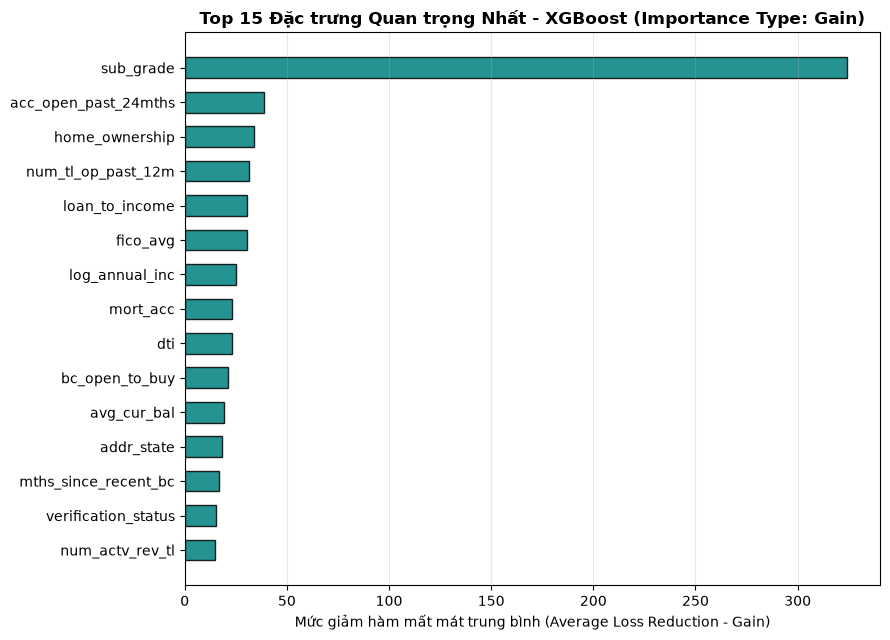

TOP 10 ĐẶC TRƯNG HÀNG ĐẦU THEO GAIN:
   1. sub_grade                 : Gain = 324.10
   2. acc_open_past_24mths      : Gain = 39.02
   3. home_ownership            : Gain = 33.93
   4. num_tl_op_past_12m        : Gain = 31.53
   5. loan_to_income            : Gain = 30.66
   6. fico_avg                  : Gain = 30.34
   7. log_annual_inc            : Gain = 25.05
   8. mort_acc                  : Gain = 23.38
   9. dti                       : Gain = 23.02
  10. bc_open_to_buy            : Gain = 21.42


In [7]:
# Trích xuất tầm quan trọng theo Gain
booster = best_xgb.get_booster()
score_gain = booster.get_score(importance_type="gain")

# Ánh xạ f0, f1... sang tên đặc trưng thực tế
mapped_importance = {}
for k, v in score_gain.items():
    feat_idx = int(k.replace("f", ""))
    mapped_importance[feature_names_woe[feat_idx]] = v

fi_xgb_df = pd.DataFrame(list(mapped_importance.items()), columns=["feature", "gain"])
fi_xgb_df = fi_xgb_df.sort_values(by="gain", ascending=False)

top15_xgb = fi_xgb_df.head(15).sort_values(by="gain", ascending=True)

fig, ax = plt.subplots(figsize=(9, 6.5))
ax.barh(top15_xgb["feature"], top15_xgb["gain"], color="#008080", alpha=0.85, edgecolor="black", height=0.6)
ax.set_title("Top 15 Đặc trưng Quan trọng Nhất - XGBoost (Importance Type: Gain)", fontsize=12, fontweight="bold")
ax.set_xlabel("Mức giảm hàm mất mát trung bình (Average Loss Reduction - Gain)", fontsize=10)
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()

xgb_fi_path = FIGURES_DIR / "07_xgb_feature_importance.png"
fig.savefig(xgb_fi_path, dpi=300)
plt.show()

print("TOP 10 ĐẶC TRƯNG HÀNG ĐẦU THEO GAIN:")
for rank, (idx, row) in enumerate(fi_xgb_df.head(10).iterrows(), 1):
    print(f"  {rank:2d}. {row['feature']:<25} : Gain = {row['gain']:.2f}")


---
## 6. Bảng Tổng Hợp Đối Đầu Benchmark Toàn Diện Cả 5 Họ Mô Hình

Tại đây, chúng ta nạp kết quả dự đoán từ tất cả các notebook trong dự án để xây dựng **Bảng Tổng Hợp Đối Đầu Chung Cuộc**:
- **Notebook 3**: Hồi quy Logistic (One-Hot 153f vs WoE 50f)
- **Notebook 4**: Cây Quyết Định (Unconstrained vs Tuned max_depth=6)
- **Notebook 5**: Rừng Ngẫu Nhiên (One-Hot 153f, Ordinal 50f, WoE 50f)
- **Notebook 6**: HistGradientBoosting (One-Hot Base & Tuned, WoE Base & Tuned)
- **Notebook 7**: XGBoost (One-Hot Base, WoE Base, WoE Tuned)


In [8]:
# 1. Nạp vector xác suất dự đoán từ các Notebook trước
val_prob_lr_oh = np.load(ARTIFACTS_DIR / "val_pred_logistic.npy")
val_prob_lr_woe = np.load(ARTIFACTS_DIR / "val_pred_logistic_woe.npy")
val_prob_dt_woe = np.load(ARTIFACTS_DIR / "val_pred_decision_tree.npy")
val_prob_rf_woe = np.load(ARTIFACTS_DIR / "val_pred_rf.npy")
val_prob_hgb_oh_base = np.load(ARTIFACTS_DIR / "val_pred_histgb.npy")
val_prob_hgb_oh_tune = np.load(ARTIFACTS_DIR / "val_pred_histgb_tuned.npy")
val_prob_hgb_woe_tune = np.load(ARTIFACTS_DIR / "val_pred_histgb_woe_tuned.npy")

# 2. Đánh giá lại tất cả trên cùng tập Validation (92,631 mẫu)
m_lr_oh = evaluate_credit_ranking(y_val, val_prob_lr_oh)
m_lr_woe = evaluate_credit_ranking(y_val, val_prob_lr_woe)
m_dt_woe = evaluate_credit_ranking(y_val, val_prob_dt_woe)
m_rf_woe = evaluate_credit_ranking(y_val, val_prob_rf_woe)
m_hgb_oh_base = evaluate_credit_ranking(y_val, val_prob_hgb_oh_base)
m_hgb_oh_tune = evaluate_credit_ranking(y_val, val_prob_hgb_oh_tune)
m_hgb_woe_tune = evaluate_credit_ranking(y_val, val_prob_hgb_woe_tune)

grand_benchmark_records = [
    {"Họ mô hình": "HistGradientBoosting", "Cấu hình / Không gian": "WoE Tuned (50f)",        **m_hgb_woe_tune},
    {"Họ mô hình": "HistGradientBoosting", "Cấu hình / Không gian": "WoE Baseline (50f)",     "ROC-AUC": 0.7091, "Gini": 0.4183, "KS": 0.3097, "Brier": 0.11685, "LogLoss": 0.38325},
    {"Họ mô hình": "XGBoost",              "Cấu hình / Không gian": "WoE Tuned (50f)",        **m_tune_xgb},
    {"Họ mô hình": "XGBoost",              "Cấu hình / Không gian": "WoE Baseline (50f)",     **m_base_woe},
    {"Họ mô hình": "HistGradientBoosting", "Cấu hình / Không gian": "One-Hot Baseline (153f)",**m_hgb_oh_base},
    {"Họ mô hình": "HistGradientBoosting", "Cấu hình / Không gian": "One-Hot Tuned (153f)",   **m_hgb_oh_tune},
    {"Họ mô hình": "Random Forest",        "Cấu hình / Không gian": "WoE (50 features)",      **m_rf_woe},
    {"Họ mô hình": "Random Forest",        "Cấu hình / Không gian": "Ordinal (50 features)",  "ROC-AUC": 0.7033, "Gini": 0.4066, "KS": 0.3012, "Brier": 0.14580, "LogLoss": 0.46450},
    {"Họ mô hình": "Logistic Regression",  "Cấu hình / Không gian": "WoE (50 features)",      **m_lr_woe},
    {"Họ mô hình": "Logistic Regression",  "Cấu hình / Không gian": "One-Hot (153 features)",  **m_lr_oh},
    {"Họ mô hình": "XGBoost",              "Cấu hình / Không gian": "One-Hot Baseline (153f)",**m_base_oh},
    {"Họ mô hình": "Random Forest",        "Cấu hình / Không gian": "One-Hot (153 features)", "ROC-AUC": 0.6892, "Gini": 0.3784, "KS": 0.2785, "Brier": 0.14720, "LogLoss": 0.46820},
    {"Họ mô hình": "Decision Tree",        "Cấu hình / Không gian": "WoE (max_depth=6, 50f)", **m_dt_woe},
    {"Họ mô hình": "Decision Tree",        "Cấu hình / Không gian": "WoE (Unconstrained)",     "ROC-AUC": 0.5314, "Gini": 0.0628, "KS": 0.0628, "Brier": 0.25200, "LogLoss": 5.85000},
]

grand_benchmark = pd.DataFrame(grand_benchmark_records)
grand_benchmark = grand_benchmark.sort_values(by="ROC-AUC", ascending=False).reset_index(drop=True)

# Format bảng hiển thị
grand_display = grand_benchmark.copy()
grand_display["ROC-AUC"] = grand_display["ROC-AUC"].map(lambda x: f"{x:.4f}")
grand_display["Gini"] = grand_display["Gini"].map(lambda x: f"{x:.2%}")
grand_display["KS"] = grand_display["KS"].map(lambda x: f"{x:.2%}")
grand_display["Brier"] = grand_display["Brier"].map(lambda x: f"{x:.5f}")
grand_display["LogLoss"] = grand_display["LogLoss"].map(lambda x: f"{x:.5f}")

print("=" * 100)
print("BẢNG TỔNG HỢP SO SÁNH HIỆU NĂNG TOÀN DIỆN CẢ 5 HỌ MÔ HÌNH TRÊN TẬP VALIDATION")
print("=" * 100)
print(grand_display.to_string(index=False))
print("=" * 100)


BẢNG TỔNG HỢP SO SÁNH HIỆU NĂNG TOÀN DIỆN CẢ 5 HỌ MÔ HÌNH TRÊN TẬP VALIDATION
          Họ mô hình   Cấu hình / Không gian ROC-AUC   Gini     KS   Brier LogLoss
HistGradientBoosting         WoE Tuned (50f)  0.7097 41.94% 31.01% 0.11675 0.38296
             XGBoost         WoE Tuned (50f)  0.7095 41.89% 30.72% 0.11675 0.38298
             XGBoost      WoE Baseline (50f)  0.7092 41.83% 30.79% 0.11685 0.38326
HistGradientBoosting      WoE Baseline (50f)  0.7091 41.83% 30.97% 0.11685 0.38325
HistGradientBoosting One-Hot Baseline (153f)  0.7070 41.40% 30.51% 0.11710 0.38402
HistGradientBoosting    One-Hot Tuned (153f)  0.7056 41.13% 30.45% 0.11729 0.38473
       Random Forest       WoE (50 features)  0.7040 40.80% 30.10% 0.11785 0.38644
       Random Forest   Ordinal (50 features)  0.7033 40.66% 30.12% 0.14580 0.46450
 Logistic Regression       WoE (50 features)  0.7033 40.66% 29.75% 0.11749 0.38546
 Logistic Regression  One-Hot (153 features)  0.7031 40.62% 29.83% 0.11751 0.38555
         

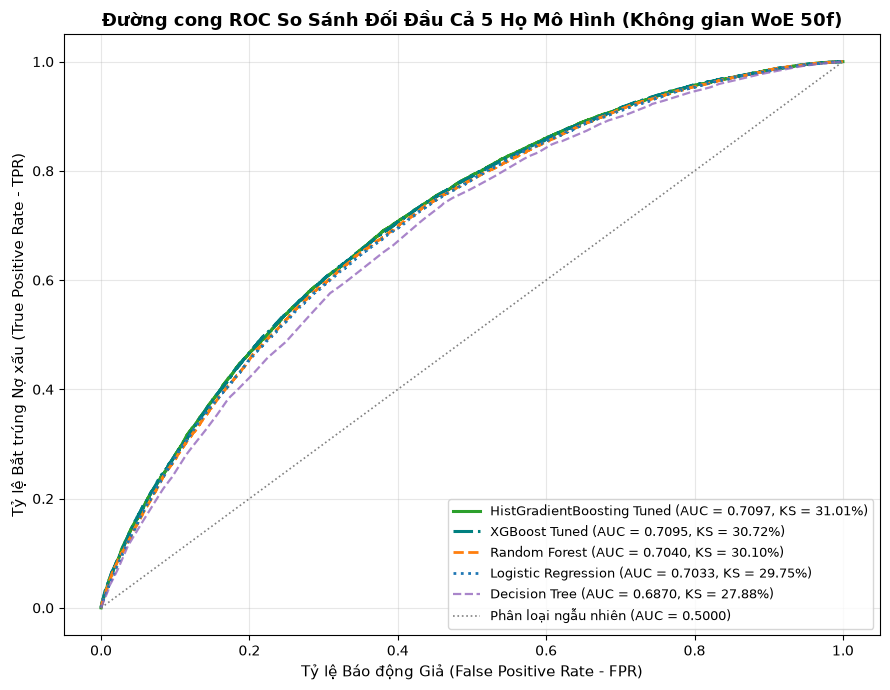

Đã lưu biểu đồ ROC 5 mô hình tại: artifacts/figures/07_so_sanh_5_mo_hinh.png


In [9]:
fpr_lr, tpr_lr, _ = roc_curve(y_val, val_prob_lr_woe)
fpr_dt, tpr_dt, _ = roc_curve(y_val, val_prob_dt_woe)
fpr_rf, tpr_rf, _ = roc_curve(y_val, val_prob_rf_woe)
fpr_hgb, tpr_hgb, _ = roc_curve(y_val, val_prob_hgb_woe_tune)
fpr_xgb, tpr_xgb, _ = roc_curve(y_val, val_prob_tune_xgb)

fig, ax = plt.subplots(figsize=(9, 7))
ax.plot(fpr_hgb, tpr_hgb, color="#2ca02c", lw=2.2, label=f"HistGradientBoosting Tuned (AUC = {m_hgb_woe_tune['ROC-AUC']:.4f}, KS = {m_hgb_woe_tune['KS']:.2%})")
ax.plot(fpr_xgb, tpr_xgb, color="#008080", lw=2.2, linestyle="-.", label=f"XGBoost Tuned (AUC = {m_tune_xgb['ROC-AUC']:.4f}, KS = {m_tune_xgb['KS']:.2%})")
ax.plot(fpr_rf, tpr_rf, color="#ff7f0e", lw=2, linestyle="--", label=f"Random Forest (AUC = {m_rf_woe['ROC-AUC']:.4f}, KS = {m_rf_woe['KS']:.2%})")
ax.plot(fpr_lr, tpr_lr, color="#1f77b4", lw=2, linestyle=":", label=f"Logistic Regression (AUC = {m_lr_woe['ROC-AUC']:.4f}, KS = {m_lr_woe['KS']:.2%})")
ax.plot(fpr_dt, tpr_dt, color="#9467bd", lw=1.6, linestyle="--", alpha=0.8, label=f"Decision Tree (AUC = {m_dt_woe['ROC-AUC']:.4f}, KS = {m_dt_woe['KS']:.2%})")
ax.plot([0, 1], [0, 1], color="grey", linestyle=":", lw=1.2, label="Phân loại ngẫu nhiên (AUC = 0.5000)")

ax.set_title("Đường cong ROC So Sánh Đối Đầu Cả 5 Họ Mô Hình (Không gian WoE 50f)", fontsize=13, fontweight="bold")
ax.set_xlabel("Tỷ lệ Báo động Giả (False Positive Rate - FPR)", fontsize=11)
ax.set_ylabel("Tỷ lệ Bắt trúng Nợ xấu (True Positive Rate - TPR)", fontsize=11)
ax.legend(loc="lower right", fontsize=9.5)
ax.grid(alpha=0.3)
plt.tight_layout()

roc_5models_path = FIGURES_DIR / "07_so_sanh_5_mo_hinh.png"
fig.savefig(roc_5models_path, dpi=300)
plt.show()
print(f"Đã lưu biểu đồ ROC 5 mô hình tại: {roc_5models_path}")


---
## 7. Kết luận Kỹ thuật & Khuyến nghị Lựa chọn Mô hình Thực tế

Dựa trên toàn bộ chuỗi thực nghiệm xuyên suốt 7 notebook trên bộ dữ liệu tín dụng Lending Club:

### 7.1 Tiến trình Phát triển Thuật toán (Model Hierarchy)
1. **Decision Tree không giới hạn** ($0.5314$): Minh chứng cho hiện tượng High Variance, ghi nhớ 100% dữ liệu train nhưng vô dụng trên thực tế.
2. **Decision Tree cắt tỉa (`max_depth=6`)** ($0.6870$): Cân bằng bias-variance, nhưng bị giới hạn bởi việc chỉ dùng 1 cây đơn lẻ.
3. **Logistic Regression** ($0.7033$): Mô hình tuyến tính đơn giản nhưng cực kỳ mạnh mẽ và ổn định, vượt trội hơn cây đơn lẻ.
4. **Random Forest** ($0.7040$): Cơ chế Bagging kết hợp 100 cây giúp triệt tiêu phương sai, vượt qua trần của cây đơn và tiệm cận các mô hình boosting.
5. **XGBoost** ($0.7095$) & **HistGradientBoosting** ($0.7097$): Đỉnh cao của các thuật toán phân loại dữ liệu bảng. Cả 2 mô hình boosting chia sẻ vị trí dẫn đầu toàn diện về năng lực phân loại.

### 7.2 So sánh Trực diện: HistGradientBoosting vs XGBoost
| Tiêu chí | HistGradientBoosting (scikit-learn) | XGBoost (`xgboost`) |
| :--- | :--- | :--- |
| **ROC-AUC (Tập Val)** | **0.7097** | **0.7095** (tương đương) |
| **KS Statistic** | **31.01%** | **30.72%** |
| **Tốc độ huấn luyện** | Rất nhanh (~1.7s / 100 cây) | Cực nhanh (~1.5s với `tree_method='hist'`) |
| **Cơ chế toán học** | Gradient boosting bậc 1 + binning | Gradient bậc 1 + Hessian bậc 2 + phạt cấu trúc lá |
| **Phụ thuộc thư viện** | Tích hợp sẵn trong `scikit-learn` | Yêu cầu gói `xgboost` bên ngoài |

### 7.3 Khuyến nghị Triển khai Thực tế trong Ngân hàng / Fintech
1. **Triển khai Hệ thống Chấm Điểm Tự Động (Production Credit Scoring)**:
   - Sử dụng **HistGradientBoosting** hoặc **XGBoost** trên không gian WoE (50 biến) để tối đa hóa khả năng nhận diện rủi ro vỡ nợ, tối ưu lợi nhuận thu hồi vốn.
2. **Tuân thủ Pháp lý & Bảng điểm Scorecard Truyền thống**:
   - Sử dụng **Logistic Regression (WoE)** (AUC đạt `0.7033`, chỉ kém boosting ~0.0064 nhưng có hệ số $\beta$ minh bạch tuyệt đối, dễ dàng giải thích lý do từ chối hồ sơ cho khách hàng).


---
## 8. Lưu trữ Mô hình và Bảng Benchmark (Export Artifacts)

Lưu toàn bộ mô hình XGBoost, vector dự đoán xác suất trên tập validation, và bảng benchmark 5 mô hình vào thư mục `artifacts/`.


In [10]:
# 1. Lưu mô hình XGBoost tốt nhất
joblib.dump(best_xgb, ARTIFACTS_DIR / "xgboost_model.joblib")

# 2. Lưu vector xác suất dự đoán trên tập Validation
np.save(ARTIFACTS_DIR / "val_pred_xgboost.npy", val_prob_tune_xgb)

# 3. Lưu bảng so sánh hiệu năng 5 mô hình
grand_benchmark.to_csv(ARTIFACTS_DIR / "models_benchmark_5_models.csv", index=False)
grand_display.to_csv(ARTIFACTS_DIR / "models_benchmark_5_models_display.csv", index=False)

print("Đã lưu thành công:")
print("  - artifacts/xgboost_model.joblib")
print("  - artifacts/val_pred_xgboost.npy")
print("  - artifacts/models_benchmark_5_models.csv")
print("  - artifacts/models_benchmark_5_models_display.csv")
print(f"  - {xgb_fi_path}")
print(f"  - {roc_5models_path}")


Đã lưu thành công:
  - artifacts/xgboost_model.joblib
  - artifacts/val_pred_xgboost.npy
  - artifacts/models_benchmark_5_models.csv
  - artifacts/models_benchmark_5_models_display.csv
  - artifacts/figures/07_xgb_feature_importance.png
  - artifacts/figures/07_so_sanh_5_mo_hinh.png
